# Week 5: Make a slider for your model

To start, save a copy to your Drive (File, then Save a copy in Drive). It needs a GPU runtime (Runtime, then Change runtime type, then A100). You will also need a Hugging Face account that has accepted the FLUX.1 [dev] license on its model page, and an access token from that account. The outputs below are from the museum chairs model in the week 5 slides.

## 1. Setup

Paste your Hugging Face token when it asks.

In [1]:
import os, sys, io, tarfile, glob
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install -U diffusers transformers accelerate peft sentencepiece
import gc, numpy as np, requests, torch
from diffusers import FluxPipeline
from diffusers.pipelines.flux.pipeline_flux import calculate_shift, retrieve_timesteps
from PIL import Image
dev = "cuda" if torch.cuda.is_available() else "mps"
if IN_COLAB:
    from huggingface_hub import notebook_login
    notebook_login()  # a Hugging Face token from an account that has accepted the FLUX.1 [dev] license
print("ready")

ready


## 2. Your model

LORA_URL starts as the museum chairs model. You can replace it with the weights link from your Replicate training, and change TRIGGER and PROMPT to describe your own images.

In [2]:
LORA_URL = "https://replicate.delivery/xezq/KdQIrXFTvNZ0BdOrYZ1i1ovkskK4qiFV8ORnLlIpfX3RMuwLA/flux-lora.tar"  # the week 5 example; paste your own weights link from Replicate
TRIGGER = "MUSCHR"
PROMPT = f"a photo of a {TRIGGER} chair, museum object photograph on a plain grey backdrop"

def get_lora(url):
    """Download the LoRA: a .safetensors file, or the .tar that Replicate's trainer returns."""
    os.makedirs("lora", exist_ok=True)
    data = requests.get(url, timeout=600).content
    if url.split("?")[0].endswith(".safetensors"):
        path = "lora/lora.safetensors"
        open(path, "wb").write(data)
        return path
    tarfile.open(fileobj=io.BytesIO(data)).extractall("lora")
    return glob.glob("lora/**/*.safetensors", recursive=True)[0]

lora_file = get_lora(LORA_URL)
print("LoRA ready:", os.path.getsize(lora_file) // 2**20, "MB")

LoRA ready: 164 MB


## 3. Two words

Write the two ends of your slider, each as a short phrase about your subject, for example "ornate chair with carved decoration" and "simple chair with no decoration". This cell also reads the three prompts with the text encoders, then frees them so the image model fits on the GPU.

In [3]:
PLUS = "ornate chair with carved decoration and tufted upholstery"
MINUS = "simple chair with straight lines and no decoration"

# encode the three prompts, then free the text encoders so the image model fits
text = FluxPipeline.from_pretrained("black-forest-labs/FLUX.1-dev", transformer=None, vae=None,
                                    torch_dtype=torch.bfloat16).to(dev)
with torch.no_grad():
    E = {k: text.encode_prompt(prompt=t, prompt_2=t, device=dev, max_sequence_length=256)
         for k, t in {"base": PROMPT, "plus": f"{PROMPT}, {PLUS}", "minus": f"{PROMPT}, {MINUS}"}.items()}
del text; gc.collect()
torch.cuda.empty_cache() if dev == "cuda" else torch.mps.empty_cache()

## 4. Load the image model

This downloads FLUX.1 [dev] and adds your LoRA, which can take several minutes the first time.

In [4]:
pipe = FluxPipeline.from_pretrained("black-forest-labs/FLUX.1-dev", text_encoder=None, text_encoder_2=None,
                                    tokenizer=None, tokenizer_2=None, torch_dtype=torch.bfloat16).to(dev)
pipe.load_lora_weights(lora_file)

H, W, STEPS, START, SEED = 896, 704, 28, 7, 7

def slider(s, seed=SEED):
    """One image with the slider at strength s. From step START on, each step adds s times the difference between
    the model's predictions for PLUS and MINUS (the target of Gandikota et al., ECCV 2024, Eq. 7)."""
    g = torch.Generator("cpu").manual_seed(seed)
    lat, img_ids = pipe.prepare_latents(1, pipe.transformer.config.in_channels // 4, H, W, torch.bfloat16, dev, g, None)
    c = pipe.scheduler.config
    mu = calculate_shift(lat.shape[1], c.get("base_image_seq_len", 256), c.get("max_image_seq_len", 4096),
                         c.get("base_shift", 0.5), c.get("max_shift", 1.15))
    ts, _ = retrieve_timesteps(pipe.scheduler, STEPS, dev, sigmas=np.linspace(1.0, 1 / STEPS, STEPS), mu=mu)
    guidance = torch.full([1], 3.5, device=dev, dtype=torch.float32)
    def predict(key, t):
        pe, pooled, ids = E[key]
        return pipe.transformer(hidden_states=lat, timestep=t.expand(1).to(lat.dtype) / 1000, guidance=guidance,
                                pooled_projections=pooled, encoder_hidden_states=pe, txt_ids=ids, img_ids=img_ids,
                                return_dict=False)[0]
    with torch.no_grad():
        for i, t in enumerate(ts):
            v = predict("base", t)
            if i >= START and s != 0:
                v = v + s * (predict("plus", t) - predict("minus", t))
            lat = pipe.scheduler.step(v, t, lat, return_dict=False)[0]
        lat = pipe._unpack_latents(lat, H, W, pipe.vae_scale_factor)
        lat = lat / pipe.vae.config.scaling_factor + pipe.vae.config.shift_factor
        return pipe.image_processor.postprocess(pipe.vae.decode(lat, return_dict=False)[0], output_type="pil")[0]

## 5. Make the strip

It makes five images with the slider at -1.5, -0.75, 0, 0.75 and 1.5, and saves them together as strip.jpg. Each image runs the model three times per step, so it takes longer than a normal image.

s = -1.50 done


s = -0.75 done


s = +0.00 done


s = +0.75 done


s = +1.50 done


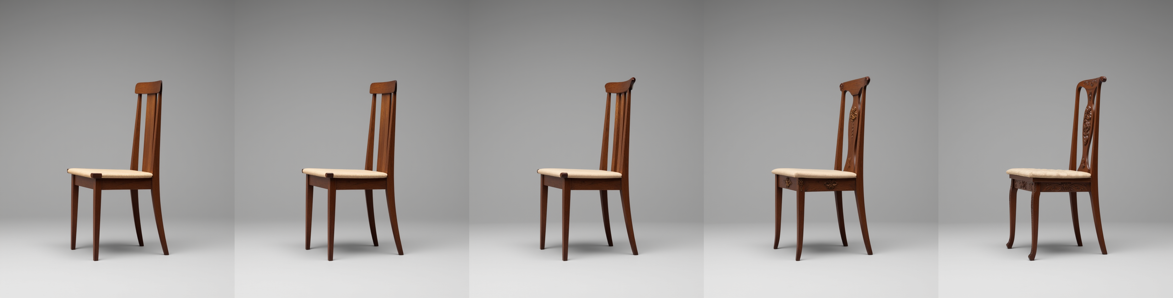

In [5]:
STRENGTHS = [-1.5, -0.75, 0, 0.75, 1.5]
strip = {}
for s in STRENGTHS:
    strip[s] = slider(s)
    strip[s].save(f"slider_{s:+.2f}.png")
    print(f"s = {s:+.2f} done")
sheet = Image.new("RGB", (W * len(STRENGTHS), H), "white")
for i, s in enumerate(STRENGTHS):
    sheet.paste(strip[s], (i * W, 0))
sheet.save("strip.jpg", quality=90)
sheet.resize((sheet.width // 3, sheet.height // 3))

## 6. Drag the slider

If the five images look the same, you can try other words or larger strengths. If the chair breaks apart, try smaller ones. For the hand-in, you can download strip.jpg from this notebook and map.jpg from the map notebook, in the Files panel on the left.

In [6]:
import ipywidgets as widgets
from IPython.display import display
view = widgets.Image(format="png", width=W // 2)
def show(change):
    buf = io.BytesIO(); strip[change["new"]].save(buf, format="png"); view.value = buf.getvalue()
pick = widgets.SelectionSlider(options=STRENGTHS, value=0, description="s", continuous_update=True)
pick.observe(show, names="value")
show({"new": 0})
display(pick, view)